# Análisis de la deserción escolar en Medellín (2017)

**Pregunta de investigación:**

> *¿Cuál es el patrón de deserción escolar en Medellín durante 2017 según el nivel educativo (grado) y el sexo?*

**Dataset:** `desercion_educativa.csv` (única fuente).

Este notebook documenta, de forma reproducible, todo el proceso de análisis: carga, limpieza, transformación, estadística descriptiva, visualización, pruebas de hipótesis e interpretación. Cada resultado puede verificarse re-ejecutando las celdas en orden.

## 1. Planteamiento y objetivos

### Contexto y problema
La **deserción escolar** es el abandono del estudiante del sistema educativo antes de completar el grado o ciclo. Este fenómeno tiene impacto directo en la trayectoria formativa de las personas y en la equidad social. En Medellín, los registros educativos oficiales del año 2017 permiten observar la deserción por establecimiento, desagregada por sexo y por cada nivel o grado.

Un primer acercamiento muestra que la deserción **no se distribuye de forma homogénea**: existen niveles educativos con tasas notablemente superiores a la media global. Identificar dónde y en qué grupos se concentra es el paso previo para orientar acciones de retención.

### Pregunta de investigación
¿Cuál es el patrón de deserción escolar en Medellín durante 2017 según el nivel educativo (grado) y el sexo?

### Objetivo general
Caracterizar y analizar la deserción escolar en Medellín durante 2017, identificando su patrón según el nivel educativo y el sexo.

### Objetivos específicos
1. Describir la distribución de la deserción por grado y nivel educativo.
2. Comparar la tasa de deserción entre hombres y mujeres.
3. Verificar, mediante pruebas de hipótesis, si las diferencias observadas son estadísticamente significativas.
4. Interpretar los hallazgos y proponer recomendaciones orientadas a la retención escolar.

### Justificación
El análisis tiene valor social (la deserción perpetúa desigualdades), institucional (permite focalizar recursos) y metodológico (transforma datos administrativos en evidencia para la toma de decisiones).

## 2. Carga y limpieza de datos

Se cargan las librerías y el dataset, y se evalúa su calidad para garantizar la validez de los análisis posteriores.

In [1]:
# -----------------------------------------------------------------------------
# 2.1 Importación de librerías.
# pandas -> estructuras tabulares; numpy -> operaciones numéricas;
# matplotlib/seaborn -> gráficos; scipy.stats -> pruebas estadísticas;
# itertools.combinations -> comparaciones por pares (post-hoc).
# -----------------------------------------------------------------------------
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from itertools import combinations

# Configuración global.
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (9, 4.5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 180)

In [2]:
# -----------------------------------------------------------------------------
# 2.2 Carga del dataset y copia de seguridad.
# Se conserva una copia del original para comparar antes/después y no sobrescribir.
# -----------------------------------------------------------------------------
df = pd.read_csv("desercion_educativa.csv")
df_original = df.copy()

print(f"Filas: {df.shape[0]} | Columnas: {df.shape[1]}")
print("Copia del original conservada en 'df_original'.")

Filas: 1134 | Columnas: 52
Copia del original conservada en 'df_original'.


In [3]:
# -----------------------------------------------------------------------------
# 2.3 Calidad de los datos: nulos y duplicados.
# isnull().sum() cuenta nulos por columna; duplicated().sum() cuenta filas repetidas.
# -----------------------------------------------------------------------------
nulos = int(df.isnull().sum().sum())
duplicados = int(df.duplicated().sum())
print(f"Valores nulos: {nulos}")
print(f"Filas duplicadas: {duplicados}")

Valores nulos: 0
Filas duplicadas: 0


**Resultado:** el dataset no presenta valores nulos ni duplicados, por lo que **no se requiere imputación ni eliminación** de registros.

In [4]:
# -----------------------------------------------------------------------------
# 2.4 Tipos de datos.
# Las variables de agrupación/identificación se convierten a 'category':
#   - reduce el uso de memoria,
#   - hace explícita su semántica (etiqueta, no cantidad).
# No se modifica ningún valor.
# -----------------------------------------------------------------------------
for col in ["establecimiento_educativo", "sector", "sexo", "codigo_dane", "comuna_establecimiento"]:
    df[col] = df[col].astype("category")

print("Tipos de dato después de la conversión:")
df.dtypes.value_counts()

Tipos de dato después de la conversión:


int64       47
category     1
category     1
category     1
category     1
category     1
Name: count, dtype: int64

In [5]:
# -----------------------------------------------------------------------------
# 2.5 Homologación de categorías.
# Se normalizan los textos (minúsculas, sin espacios laterales) para evitar
# categorías duplicadas por diferencias de escritura.
# -----------------------------------------------------------------------------
for col in ["establecimiento_educativo", "sector", "sexo"]:
    df[col] = df[col].astype(str).str.strip().str.lower().astype("category")

print("Categorías finales:")
print("  sector:", sorted(df["sector"].unique()))
print("  sexo:  ", sorted(df["sexo"].unique()))

Categorías finales:
  sector: ['cobertura contratada', 'no oficial', 'oficial', 'regimen especial']
  sexo:   ['hombres', 'mujeres']


In [6]:
# -----------------------------------------------------------------------------
# 2.6 Consistencia lógica.
# Regla de negocio: la deserción nunca debe superar la matrícula.
# Se separan las columnas por prefijo y se comparan los totales por fila.
# -----------------------------------------------------------------------------
columnas_desercion = [c for c in df.columns if c.startswith("desercion")]
columnas_matricula = [c for c in df.columns if c.startswith("matricula")]

total_desercion = df[columnas_desercion].sum(axis=1)
total_matricula = df[columnas_matricula].sum(axis=1)

inconsistentes = int((total_desercion > total_matricula).sum())
negativos = int((df.select_dtypes("number") < 0).sum().sum())

print(f"Columnas de deserción: {len(columnas_desercion)}")
print(f"Columnas de matrícula: {len(columnas_matricula)}")
print(f"Filas con deserción > matrícula: {inconsistentes}")
print(f"Celdas con valores negativos: {negativos}")

Columnas de deserción: 23
Columnas de matrícula: 23
Filas con deserción > matrícula: 0
Celdas con valores negativos: 0


**Conclusión de la limpieza.** El dataset es de buena calidad: sin nulos, duplicados, negativos ni inconsistencias. La limpieza se limitó a normalizar tipos y categorías, **sin pérdida de información**.

## 3. Transformación: totales, tasa y formato largo

Se derivan las variables necesarias para responder la pregunta. La medida central es la **tasa de deserción**, que relativiza el número de desertores respecto a la matrícula:

$$\text{tasa} = \frac{\text{deserciones}}{\text{matrícula}} \times 100\,$$

Usar la tasa (y no el conteo absoluto) permite comparar establecimientos y niveles de distinto tamaño. La columna `codigo_dane` identifica cada establecimiento y `sexo` distingue hombres y mujeres.

In [7]:
# -----------------------------------------------------------------------------
# 3.1 Totales y tasa por registro.
# np.where evita la división entre cero (cuando la matrícula es 0, la tasa es 0).
# -----------------------------------------------------------------------------
df["total_desercion"] = total_desercion
df["total_matricula"] = total_matricula
df["tasa_desercion"] = np.where(
    df["total_matricula"] > 0,
    df["total_desercion"] / df["total_matricula"] * 100,
    0.0
)

print("Totales y tasa calculados para", df.shape[0], "registros.")

Totales y tasa calculados para 1134 registros.


In [8]:
# -----------------------------------------------------------------------------
# 3.2 Formato largo (una fila por establecimiento × sexo × grado).
# Cada par de columnas (desercion_*, matricula_*) se apila en una sola fila,
# añadiendo la columna 'grado'. Facilita la agregación por nivel educativo.
# -----------------------------------------------------------------------------
filas = []
for d, m in zip(columnas_desercion, columnas_matricula):
    grado = d.replace("desercion_grado_", "").replace("desercion_", "")
    par = df[["codigo_dane", "sexo"]].copy()
    par["grado"] = grado
    par["desercion"] = df[d]
    par["matricula"] = df[m]
    filas.append(par)
df_largo = pd.concat(filas, ignore_index=True)

# Tasa por grado-establecimiento-sexo.
df_largo["tasa"] = np.where(
    df_largo["matricula"] > 0,
    df_largo["desercion"] / df_largo["matricula"] * 100,
    0.0
)

print(f"Formato largo: {df_largo.shape[0]} filas × {df_largo.shape[1]} columnas")
df_largo.head()

Formato largo: 26082 filas × 6 columnas


,codigo_dane,sexo,grado,desercion,matricula,tasa
0,105001000001,hombres,prejardin,0,0,0.000000
1,105001000001,mujeres,prejardin,0,0,0.000000
2,105001000043,hombres,prejardin,0,0,0.000000
3,105001000043,mujeres,prejardin,0,0,0.000000
4,105001000094,hombres,prejardin,1,60,1.666667


In [9]:
# -----------------------------------------------------------------------------
# 3.3 Clasificación del grado en dos tipos de educación.
# 'clei' en el nombre -> educación para adultos; el resto -> educación regular.
# -----------------------------------------------------------------------------
df_largo["tipo"] = np.where(
    df_largo["grado"].str.contains("clei"),
    "Educación para adultos",
    "Educación regular"
)

print(df_largo["tipo"].value_counts().to_string())

tipo
Educación regular         19278
Educación para adultos     6804


**Resultado.** Se dispone de dos estructuras: `df` (un registro por establecimiento × sexo, con totales y tasa) y `df_largo` (una fila por grado, con su tasa y su tipo de educación).

## 4. Estadística descriptiva

Se resumen las variables principales con medidas de **tendencia central** (media, mediana) y de **dispersión** (desviación estándar, varianza, percentiles).

In [10]:
# Medidas descriptivas de deserción, matrícula y tasa.
# describe() calcula media, desviación, mínimos y cuartiles; se añade la varianza.
desc = df[["total_desercion", "total_matricula", "tasa_desercion"]].describe().T
desc["varianza"] = df[["total_desercion", "total_matricula", "tasa_desercion"]].var()
desc = desc[["count", "mean", "std", "varianza", "min", "50%", "max"]]
desc.round(2)

,count,mean,std,varianza,min,50%,max
total_desercion,1134.0,12.75,26.78,716.91,0.0,1.00,295.0
total_matricula,1134.0,400.97,453.58,205732.44,0.0,240.00,3061.0
tasa_desercion,1134.0,2.56,5.40,29.21,0.0,0.18,100.0


In [11]:
# Percentiles de la tasa de deserción.
df["tasa_desercion"].quantile([0.25, 0.50, 0.75, 0.90, 0.95, 0.99]).round(2)

0.25     0.00
0.50     0.18
0.75     3.40
0.90     6.85
0.95    10.31
0.99    25.00
Name: tasa_desercion, dtype: float64

In [12]:
# Tasa global de deserción (total del conjunto).
tasa_global = df["total_desercion"].sum() / df["total_matricula"].sum() * 100
print(f"Tasa global de deserción: {tasa_global:.2f}%")

Tasa global de deserción: 3.18%


**Interpretación.** La mediana de la tasa (0,18\%) es mucho menor que la media (2,56\%), lo que indica una distribución asimétrica positiva. La tasa global es del 3,18\%.

## 5. Análisis descriptivo por grupo

Se agrega la deserción por **nivel educativo (grado)**, por **tipo de educación**, por **sexo** y por **sector**, para identificar dónde y en quién se concentra el fenómeno.

In [13]:
# Etiqueta legible para los grados: 'clei1' -> 'educación para adultos 1'.
def etiqueta_grado(g):
    if "clei" in g:
        return f"educación para adultos {g.replace('clei', '')}"
    return f"grado {g}"

# Tasa por grado (agregando deserción y matrícula).
por_grado = df_largo.groupby("grado").agg(
    desercion=("desercion", "sum"),
    matricula=("matricula", "sum")).reset_index()
por_grado["grado_legible"] = por_grado["grado"].apply(etiqueta_grado)
por_grado["tasa"] = (por_grado["desercion"] / por_grado["matricula"] * 100).round(2)
por_grado = por_grado.sort_values("tasa", ascending=False)

In [14]:
# Tasa por tipo de educación (adultos vs. regular).
por_tipo = df_largo.groupby("tipo").agg(
    desercion=("desercion", "sum"),
    matricula=("matricula", "sum")).reset_index()
por_tipo["tasa"] = (por_tipo["desercion"] / por_tipo["matricula"] * 100).round(2)
por_tipo

,tipo,desercion,matricula,tasa
0,Educación para adultos,4331,41368,10.47
1,Educación regular,10126,413335,2.45


In [15]:
# Tasa por sexo.
por_sexo = df.groupby("sexo", observed=True).agg(
    desercion=("total_desercion", "sum"),
    matricula=("total_matricula", "sum")).reset_index()
por_sexo["tasa"] = (por_sexo["desercion"] / por_sexo["matricula"] * 100).round(2)
por_sexo

,sexo,desercion,matricula,tasa
0,hombres,8046,226890,3.55
1,mujeres,6411,227813,2.81


In [16]:
# Tasa por sector.
por_sector = df.groupby("sector", observed=True).agg(
    desercion=("total_desercion", "sum"),
    matricula=("total_matricula", "sum")).reset_index()
por_sector["tasa"] = (por_sector["desercion"] / por_sector["matricula"] * 100).round(2)
por_sector = por_sector.sort_values("tasa", ascending=False)
por_sector

,sector,desercion,matricula,tasa
0,cobertura contratada,2571,45802,5.61
2,oficial,10669,327924,3.25
1,no oficial,1217,80858,1.51
3,regimen especial,0,119,0.00


In [17]:
# Top de niveles con mayor deserción.
por_grado[["grado_legible", "desercion", "matricula", "tasa"]].head(10)

,grado_legible,desercion,matricula,tasa
13,educación para adultos 1,64,175,36.57
14,educación para adultos 2,243,1351,17.99
15,educación para adultos 3,1478,9026,16.37
16,educación para adultos 4,1265,11625,10.88
17,educación para adultos 5,732,9122,8.02
18,educación para adultos 6,549,10069,5.45
9,grado 6,2057,44071,4.67
10,grado 7,1216,37038,3.28
0,grado 1,975,33409,2.92
11,grado 8,915,33397,2.74


**Interpretación.** La educación para adultos presenta la tasa más alta (10,47\%), más de cuatro veces la de la educación regular (2,45\%). En la educación regular, el pico se ubica en el **grado 6** (4,67\%), seguido del grado 7 (3,28\%). La diferencia entre hombres (3,55\%) y mujeres (2,81\%) es pequeña. Por sector, la **cobertura contratada** lidera (5,61\%).

## 6. Visualización de resultados

Las gráficas complementan las tablas al evidenciar visualmente dónde se concentra la deserción y cómo se compara entre grupos.

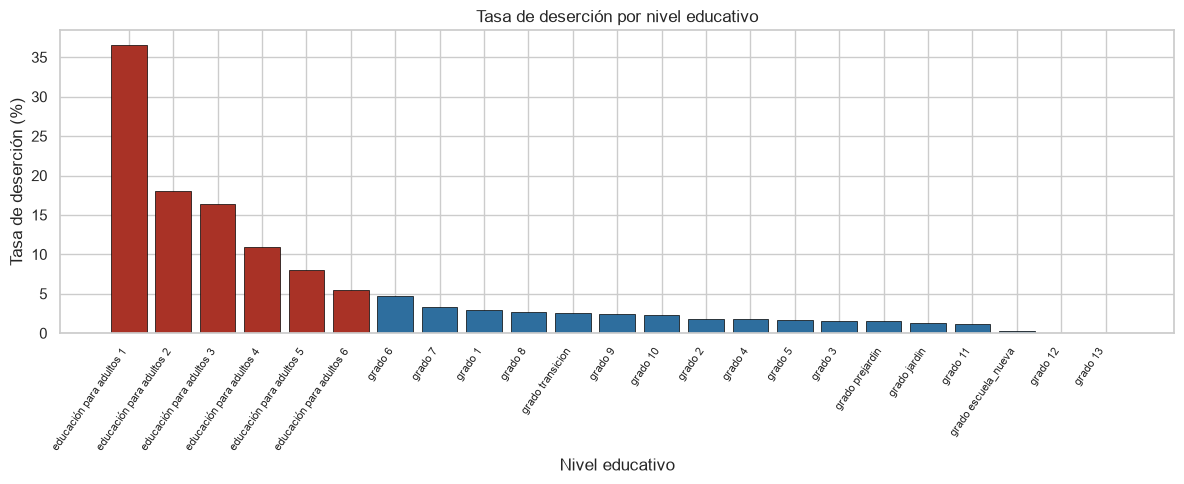

In [18]:
# Gráfico 1: tasa de deserción por nivel educativo.
# Rojo = educación para adultos; azul = educación regular.
es_adulto = por_grado["grado"].str.contains("clei")
colores = ["#a93226" if a else "#2e6e9e" for a in es_adulto]

plt.figure(figsize=(12, 5))
plt.bar(por_grado["grado_legible"], por_grado["tasa"], color=colores, edgecolor="black", linewidth=0.5)
plt.title("Tasa de deserción por nivel educativo")
plt.ylabel("Tasa de deserción (%)")
plt.xlabel("Nivel educativo")
plt.xticks(rotation=55, ha="right", fontsize=8)
plt.tight_layout()
plt.show()

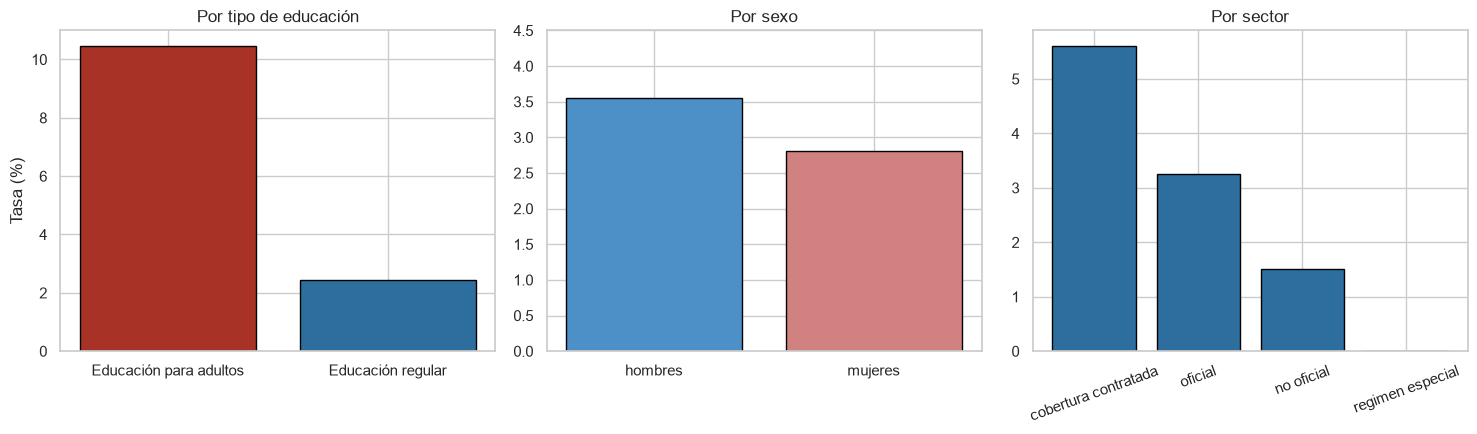

In [19]:
# Gráfico 2: comparación por tipo, sexo y sector (tres paneles).
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

axes[0].bar(por_tipo["tipo"], por_tipo["tasa"], color=["#a93226", "#2e6e9e"], edgecolor="black")
axes[0].set_title("Por tipo de educación")
axes[0].set_ylabel("Tasa (%)")

axes[1].bar(por_sexo["sexo"], por_sexo["tasa"], color=["#4d8fc7", "#d28181"], edgecolor="black")
axes[1].set_title("Por sexo")
axes[1].set_ylim(0, 4.5)

axes[2].bar(por_sector["sector"], por_sector["tasa"], color="#2e6e9e", edgecolor="black")
axes[2].set_title("Por sector")
axes[2].tick_params(axis="x", rotation=20)

plt.tight_layout()
plt.show()

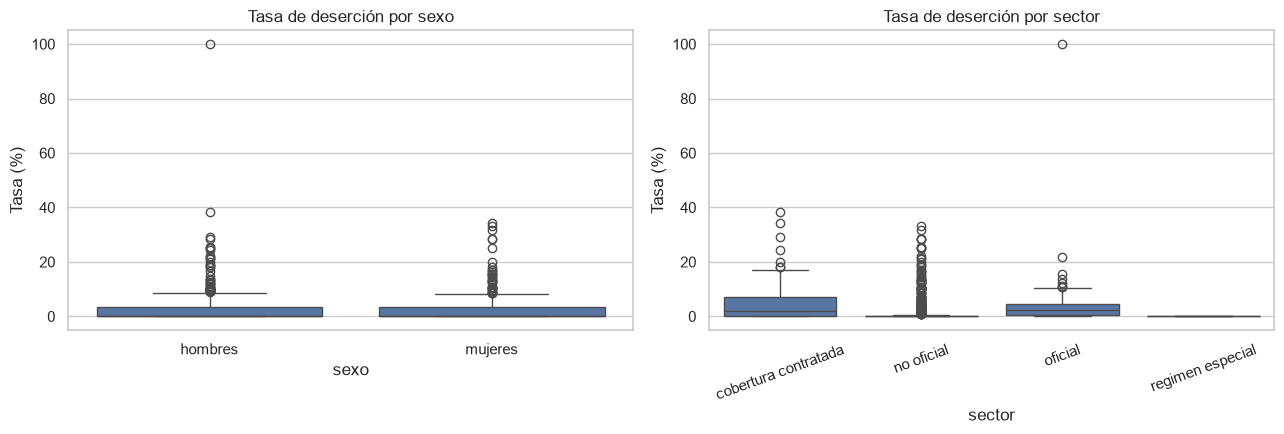

In [20]:
# Gráfico 3: boxplot de la tasa por sexo y por sector.
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.boxplot(data=df, x="sexo", y="tasa_desercion", ax=axes[0])
axes[0].set_title("Tasa de deserción por sexo")
axes[0].set_ylabel("Tasa (%)")
sns.boxplot(data=df, x="sector", y="tasa_desercion", ax=axes[1])
axes[1].set_title("Tasa de deserción por sector")
axes[1].set_ylabel("Tasa (%)")
axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout()
plt.show()

**Interpretación.** El gráfico 1 evidencia que las barras rojas (educación para adultos) dominan ampliamente, con la educación para adultos 1 alcanzando 36,57\%. El gráfico 3 muestra que la distribución de la tasa por sexo es muy similar (medianas casi idénticas), mientras que por sector la cobertura contratada exhibe mayor dispersión y tasas más altas.

## 7. Análisis de correlación

Se evalúa la relación entre la matrícula y la deserción totales. Dado que la tasa no sigue una distribución normal, se emplea la **correlación de Spearman** (no paramétrica).

In [21]:
# Correlación de Spearman entre matrícula y deserción totales.
rho, p_corr = stats.spearmanr(df["total_matricula"], df["total_desercion"])
print(f"Spearman: ρ = {rho:.3f} | p = {p_corr:.2e}")

Spearman: ρ = 0.666 | p = 1.97e-146


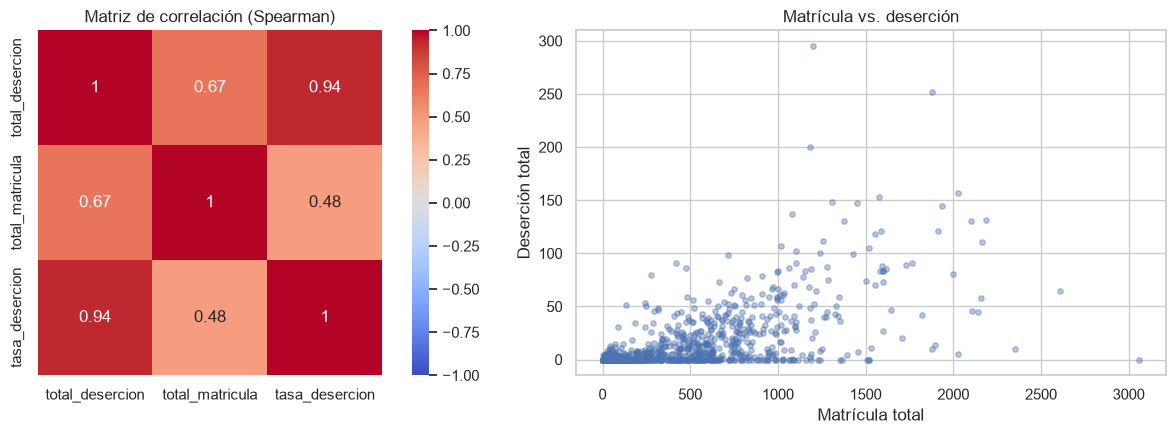

In [22]:
# Matriz de correlación y gráfico de dispersión.
matriz_corr = df[["total_desercion", "total_matricula", "tasa_desercion"]].corr(method="spearman")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.heatmap(matriz_corr, annot=True, cmap="coolwarm", vmin=-1, vmax=1, square=True, ax=axes[0])
axes[0].set_title("Matriz de correlación (Spearman)")

axes[1].scatter(df["total_matricula"], df["total_desercion"], alpha=0.4, s=15)
axes[1].set_title("Matrícula vs. deserción")
axes[1].set_xlabel("Matrícula total")
axes[1].set_ylabel("Deserción total")
plt.tight_layout()
plt.show()

**Interpretación.** Existe una correlación positiva y significativa (ρ = 0,67; p < 0,001): los establecimientos con mayor matrícula acumulan más deserciones absolutas. Este resultado es esperable y **no implica causalidad**: que un establecimiento sea grande no *causa* la deserción, simplemente concentra más estudiantes y, por tanto, más casos.

## 8. Valores atípicos

Se detectan valores extremos de la deserción total mediante el **rango intercuartílico (IQR)**, interpretándolos y justificando su tratamiento.

In [23]:
# Rango intercuartílico sobre la deserción total.
q1 = df["total_desercion"].quantile(0.25)
q3 = df["total_desercion"].quantile(0.75)
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr

atipicos = df[df["total_desercion"] > lim_sup]
print(f"Q1 = {q1:.2f} | Q3 = {q3:.2f} | IQR = {iqr:.2f}")
print(f"Límite superior = {lim_sup:.2f}")
print(f"Registros atípicos: {len(atipicos)} ({len(atipicos)/len(df)*100:.1f}%)")

Q1 = 0.00 | Q3 = 13.00 | IQR = 13.00
Límite superior = 32.50
Registros atípicos: 158 (13.9%)


**Interpretación y decisión.** Los valores atípicos corresponden a establecimientos con gran matrícula y a programas de educación para adultos, cuya deserción es estructuralmente alta. **Se conservan** porque reflejan un fenómeno real (no errores de captura), y eliminarlos ocultaría justamente los casos de mayor interés para el análisis.

## 9. Pruebas de hipótesis

Se contrastan estadísticamente las diferencias observadas. Se usa un nivel de significancia **α = 0,05**:
- Si **p < 0,05**, se rechaza la hipótesis nula (hay diferencia significativa).
- Si **p ≥ 0,05**, no se rechaza la nula (no hay evidencia de diferencia).

Puesto que la tasa no es normal, se emplean **pruebas no paramétricas**.

In [24]:
# -----------------------------------------------------------------------------
# 9.1 Normalidad de la tasa (Shapiro-Wilk).
# H0: la tasa sigue una distribución normal. H1: no la sigue.
# -----------------------------------------------------------------------------
W, p_norm = stats.shapiro(df["tasa_desercion"])
print(f"Shapiro-Wilk: W = {W:.4f} | p = {p_norm:.2e}")
print("→", "Distribución normal" if p_norm > 0.05 else "NO normal → usar no paramétricas")

Shapiro-Wilk: W = 0.4832 | p = 3.81e-49
→ NO normal → usar no paramétricas


**Interpretación.** La tasa no sigue una distribución normal (p < 0,001), lo que justifica el uso de pruebas no paramétricas en las comparaciones siguientes.

In [25]:
# -----------------------------------------------------------------------------
# 9.2 Comparación: educación para adultos vs. regular (Mann-Whitney U).
# H0: no hay diferencia de deserción entre ambos tipos de educación.
# H1: sí hay diferencia.
# -----------------------------------------------------------------------------
adultos = df_largo.loc[df_largo["tipo"] == "Educación para adultos", "tasa"]
regular = df_largo.loc[df_largo["tipo"] == "Educación regular", "tasa"]
U1, p1 = stats.mannwhitneyu(regular, adultos, alternative="two-sided")
print(f"Mann-Whitney U = {U1:.2f} | p = {p1:.2e}")

Mann-Whitney U = 70795459.00 | p = 1.62e-61


In [26]:
# -----------------------------------------------------------------------------
# 9.3 Comparación entre grados (Kruskal-Wallis).
# H0: todos los grados tienen la misma tasa. H1: al menos uno difiere.
# -----------------------------------------------------------------------------
grupos_grado = [df_largo.loc[df_largo["grado"] == g, "tasa"] for g in df_largo["grado"].unique()]
H2, p2 = stats.kruskal(*grupos_grado)
print(f"Kruskal-Wallis (grados): H = {H2:.2f} | p = {p2:.2e}")

Kruskal-Wallis (grados): H = 1804.72 | p = 0.00e+00


In [27]:
# -----------------------------------------------------------------------------
# 9.4 Comparación entre sectores (Kruskal-Wallis).
# H0: todos los sectores tienen la misma tasa. H1: al menos uno difiere.
# -----------------------------------------------------------------------------
grupos_sector = [df.loc[df["sector"] == s, "tasa_desercion"] for s in df["sector"].unique()]
H3, p3 = stats.kruskal(*grupos_sector)
print(f"Kruskal-Wallis (sectores): H = {H3:.2f} | p = {p3:.2e}")

Kruskal-Wallis (sectores): H = 232.09 | p = 4.88e-50


In [28]:
# -----------------------------------------------------------------------------
# 9.5 Comparación por sexo (Mann-Whitney U).
# H0: no hay diferencia de deserción entre hombres y mujeres. H1: sí la hay.
# -----------------------------------------------------------------------------
hombres = df.loc[df["sexo"] == "hombres", "tasa_desercion"]
mujeres = df.loc[df["sexo"] == "mujeres", "tasa_desercion"]
U5, p5 = stats.mannwhitneyu(hombres, mujeres, alternative="two-sided")
print(f"Mann-Whitney U (sexo) = {U5:.2f} | p = {p5:.4f}")

Mann-Whitney U (sexo) = 161550.00 | p = 0.8765


**Interpretación conjunta.**
- **Tipo de educación (adultos vs. regular):** p < 0,001 → diferencia **significativa**.
- **Entre grados:** p < 0,001 → diferencias **significativas**.
- **Entre sectores:** p < 0,001 → diferencias **significativas**.
- **Por sexo:** p = 0,88 → diferencia **NO significativa**.

El sexo no es un factor discriminante, a pesar de la pequeña diferencia en las tasas brutas.

In [29]:
# -----------------------------------------------------------------------------
# 9.6 Comparaciones post-hoc entre grados (Bonferroni).
# Kruskal-Wallis indica que HAY diferencias, pero no DÓNDE. Se comparan pares de
# grados con Mann-Whitney U y corrección de Bonferroni (α / nº comparaciones).
# Se excluyen grados con matrícula < 100 para evitar comparaciones poco fiables.
# -----------------------------------------------------------------------------
matricula_por_grado = df_largo.groupby("grado")["matricula"].sum()
grados_utiles = matricula_por_grado[matricula_por_grado >= 100].index.tolist()

n_comp = len(list(combinations(grados_utiles, 2)))
alpha_bonf = 0.05 / n_comp

pares_significativos = []
for g1, g2 in combinations(sorted(grados_utiles), 2):
    _, p_par = stats.mannwhitneyu(
        df_largo.loc[df_largo["grado"] == g1, "tasa"],
        df_largo.loc[df_largo["grado"] == g2, "tasa"],
        alternative="two-sided")
    if p_par < alpha_bonf:
        pares_significativos.append((g1, g2, p_par))

print(f"Grados comparados: {len(grados_utiles)}")
print(f"Pares evaluados: {n_comp} | Nivel corregido (Bonferroni): {alpha_bonf:.2e}")
print(f"Pares con diferencia significativa: {len(pares_significativos)}")

Grados comparados: 21
Pares evaluados: 210 | Nivel corregido (Bonferroni): 2.38e-04
Pares con diferencia significativa: 147


In [30]:
# Pares que involucran la educación para adultos o el grado 6 (los puntos críticos).
relevantes = [p for p in pares_significativos
              if "clei" in p[0] or "clei" in p[1] or p[0] == "6" or p[1] == "6"]
for g1, g2, p_par in sorted(relevantes, key=lambda x: x[2])[:12]:
    print(f"{g1} vs {g2}: p = {p_par:.2e}")

6 vs escuela_nueva: p = 1.95e-80
6 vs clei1: p = 2.07e-68
7 vs clei1: p = 3.23e-60
8 vs clei1: p = 9.21e-57
1 vs clei1: p = 1.83e-55
6 vs jardin: p = 1.66e-50
9 vs clei1: p = 9.87e-50
6 vs prejardin: p = 3.56e-48
clei1 vs transicion: p = 9.51e-48
6 vs clei2: p = 1.15e-46
10 vs clei1: p = 1.96e-46
5 vs clei1: p = 4.01e-44


**Interpretación.** Las comparaciones post-hoc confirman que las diferencias más marcadas involucran a los ciclos de **educación para adultos** y al **grado 6**, reforzando el hallazgo principal del análisis.

## 10. Síntesis de resultados

| Análisis | Resultado | Conclusión |
|---|---|---|
| Tasa global | 3,18% | Valor de referencia |
| Adultos vs. regular | 10,47% vs. 2,45% | Diferencia significativa (p < 0,001) |
| Pico en regular | grado 6: 4,67% | Punto crítico de transición |
| Por sexo | 3,55% vs. 2,81% | No significativa (p = 0,88) |
| Por sector | cobertura contratada 5,61% | Diferencia significativa (p < 0,001) |
| Correlación matrícula-deserción | ρ = 0,67 | Asociación, no causalidad |

La deserción se concentra en la **educación para adultos** y, dentro de la regular, en el **grado 6**. El **sexo no es un factor discriminante**.

## 11. Conclusiones, limitaciones y recomendaciones

### Conclusiones
El patrón de deserción en Medellín 2017 depende del **nivel educativo** —se concentra en la educación para adultos (10,47\%) y en el grado 6 (4,67\%)— y **no del sexo** (p = 0,88). El sector también es relevante: la cobertura contratada registra la mayor tasa (5,61\%).

### Limitaciones
- Un solo año (2017); sin variables socioeconómicas.
- Las relaciones son asociaciones estadísticas, no causales.

### Recomendaciones
1. Priorizar la retención en la educación para adultos.
2. Acompañar la transición a secundaria (grados 6-7).
3. Revisar el sector de cobertura contratada.
4. Monitorear la deserción por nivel y establecimiento.